<table border=0 width="100%"><tr><td><font size=5><B>week04-homework-api-data</B></font></td></tr></table>

# 第四周作业：选择1家上市公司并结合tushare获取数据进行分析
- 自由选择1家感兴趣的上市公司；
- 针对你选择的公司，提出一个你感兴趣的问题；
- 应用tushare获取与该公司相关的数据（不限于股市价格数据、财务等数据，国家宏观等数据均可使用）；
- 尝试应用你采集的数据做数据分析，回答你提出的问题。


提交作业：
- 在线提交：http://swufe.fanya.chaoxing.com/portal
- 截止日期：2026年10月16日晚上8点
- 提交**这个jupyter文档**，命名为“week04-homework-api-data_学号_姓名.ipynb”，学号姓名替换为自己的学号和姓名
- jupyter文档你要完成的包括四部分：公司名称与基本简介、研究问题题目及其内涵介绍、数据采集、数据分析与问题解答
- 为了批改方便，我这里将tushare token直接放到代码中

# 第一部分：公司名称与基本简介

比亚迪股份有限公司（002594.SZ）

比亚迪成立于1994年11月，总部位于深圳市坪山区。公司是一家横跨汽车、轨道交通、新能源和电子四大产业的高新技术企业，专注于能源的获取、存储与应用，致力于提供零排放的新能源整体解决方案。公司于2002年7月在香港联交所主板上市（H股代码01211），2011年6月在深交所上市（A股代码002594）。业务与品牌布局中国新能源汽车龙头企业，业务覆盖汽车、轨道交通、新能源和电子四大产业。2022年宣布停产燃油车，全面转型新能源。近年销量波动明显：2026年4月新能源汽车销量321,123辆，累计同比下滑26.02%；但2026年9月单月乘用车销量回升至456,713辆。比亚迪已构建“王朝”与“海洋”两大主品牌系列，覆盖大众市场；同时推出腾势、方程豹、仰望三大子品牌，分别定位豪华、个性越野与超高端市场。在技术领域，公司拥有刀片电池、DM-i超级混动、e平台3.0、超级e平台、DiSus智能车身控制系统等核心技术，并于2026年推出第二代刀片电池及闪充技术，可实现“充电5分钟续航约400公里”。

# 第二部分：研究问题题目及其内涵介绍

问题：比亚迪销量一路狂飙，但股价却没跟着同步起飞，销量增长与股价表现到底是否匹配？业绩与股价是否匹配？
内涵介绍：
    比亚迪是典型的“成长股”，市场对其股价的预期很大程度上取决于销量增速。但现实中经常出现“销量涨、股价跌”或“销量跌、股价稳”的矛盾现象。这种现象也让我产生疑惑市场到底是根据什么进行定价？如果股价与销量高度相关，那么可以看出市场是主要的推动力，投资者可以根据销量做判断。如果相关性弱甚至出现相反的现象，说明市场更关注利润率、竞争格局、估值水平等非销量因素，此时投资者需要看相关的报表这些进行分析。
    同时这个问题可以用 tushare 来回答，结论有讨论空间。

# 第三部分：数据采集

In [1]:
%pip install tushare

Note: you may need to restart the kernel to use updated packages.


In [2]:
import tushare as ts
# 为了批改方便，我这里将tushare token直接放到代码中
token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

In [3]:
import tushare as ts
import pandas as pd

token = "5c426f5af978fd42fe0f81fe7e60c02ada33d6c79347b61ccb44f521"
ts.set_token(token=token)
pro = ts.pro_api()

# 取比亚迪日线数据
byd = pro.daily(ts_code='002594.SZ', start_date='20200101', end_date='20241231')
byd['trade_date'] = pd.to_datetime(byd['trade_date'])
byd = byd.sort_values('trade_date').reset_index(drop=True)

print(byd.head())
print(byd.shape)

     ts_code trade_date   open   high    low  close  pre_close  change  \
0  002594.SZ 2020-01-02  47.69  48.47  47.51  48.17      47.67    0.50   
1  002594.SZ 2020-01-03  48.20  48.99  47.68  48.04      48.17   -0.13   
2  002594.SZ 2020-01-06  47.39  49.19  47.19  48.28      48.04    0.24   
3  002594.SZ 2020-01-07  48.31  48.50  47.77  48.05      48.28   -0.23   
4  002594.SZ 2020-01-08  47.55  48.35  47.15  47.28      48.05   -0.77   

   pct_chg        vol      amount  
0   1.0489  159345.70  765516.493  
1  -0.2699  129936.07  628361.961  
2   0.4996  169871.38  822172.472  
3  -0.4764   93400.58  449013.435  
4  -1.6025  110974.45  529249.404  
(1212, 11)


In [4]:
index_ne = pro.index_daily(ts_code='399976.SZ', start_date='20200101', end_date='20241231')
index_ne['trade_date'] = pd.to_datetime(index_ne['trade_date'])
index_ne = index_ne.sort_values('trade_date').reset_index(drop=True)
print(index_ne.shape)

(1212, 11)


# 第四部分：数据分析过程

In [5]:
%pip install matplotlib

Note: you may need to restart the kernel to use updated packages.


In [6]:
import tushare as ts
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']   # 正常显示中文
plt.rcParams['axes.unicode_minus'] = False     # 正常显示负号

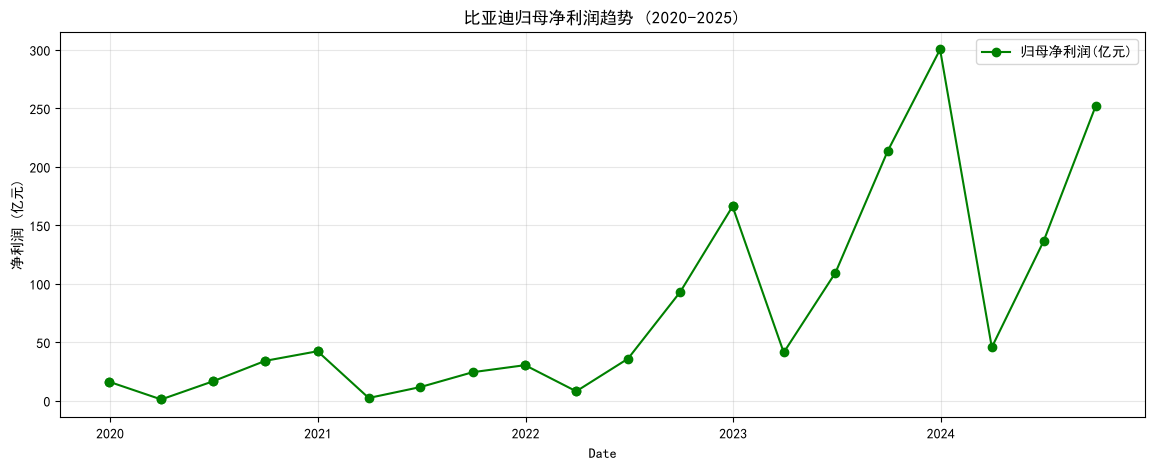

In [7]:
# ===== 净利润趋势图 =====
income = pro.income(ts_code='002594.SZ', start_date='20200101', end_date='20241231',
                    fields='end_date,revenue,n_income_attr_p')
income['end_date'] = pd.to_datetime(income['end_date'])
income = income.sort_values('end_date').reset_index(drop=True)

plt.figure(figsize=(14, 5))
plt.plot(income['end_date'], income['n_income_attr_p']/1e8, 
         marker='o', color='green', label='归母净利润(亿元)')
plt.title('比亚迪归母净利润趋势 (2020-2025)')
plt.xlabel('Date')
plt.ylabel('净利润 (亿元)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

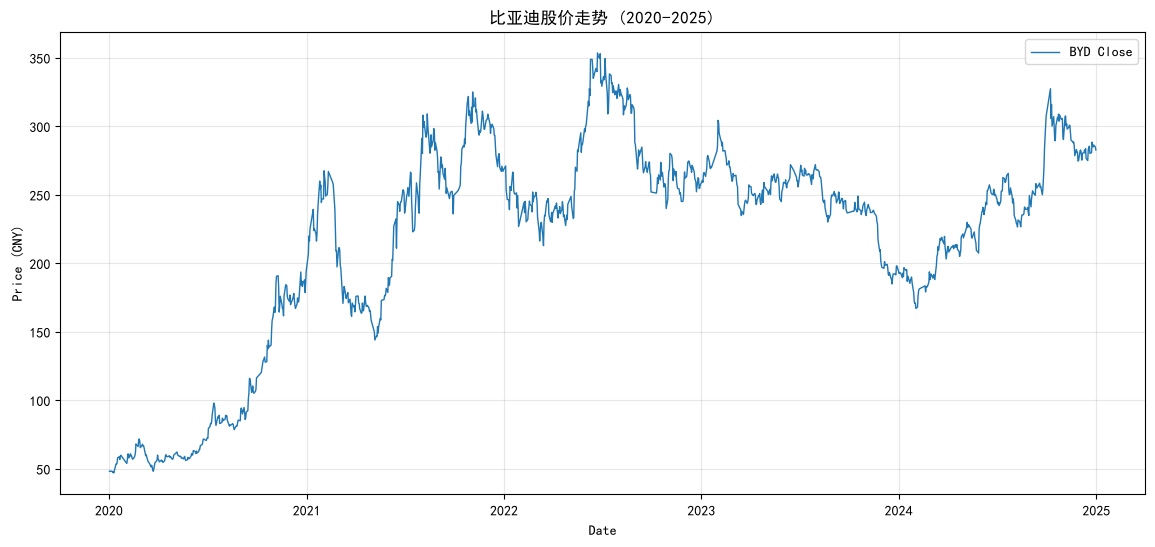

In [8]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

plt.figure(figsize=(14, 6))
plt.plot(byd['trade_date'], byd['close'], label='BYD Close', linewidth=1)
plt.title('比亚迪股价走势 (2020-2025)')
plt.xlabel('Date')
plt.ylabel('Price (CNY)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [9]:
byd['return'] = byd['close'].pct_change()
annual_return = byd['return'].mean() * 252
annual_vol = byd['return'].std() * (252 ** 0.5)
print(f"年化收益率: {annual_return:.2%}")
print(f"年化波动率: {annual_vol:.2%}")

年化收益率: 47.23%
年化波动率: 45.79%


            byd_ret  index_ret
byd_ret    1.000000   0.717571
index_ret  0.717571   1.000000


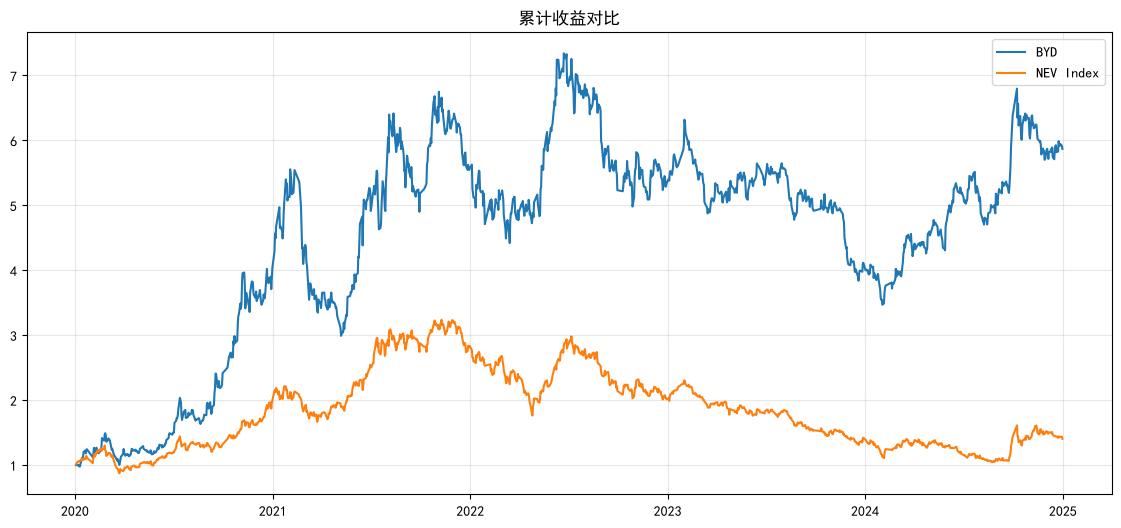

In [10]:
merged = pd.merge(byd[['trade_date','close']], 
                  index_ne[['trade_date','close']], 
                  on='trade_date', suffixes=('_byd','_index'))

merged['byd_ret'] = merged['close_byd'].pct_change()
merged['index_ret'] = merged['close_index'].pct_change()

corr = merged[['byd_ret','index_ret']].corr()
print(corr)

merged['cum_byd'] = (1 + merged['byd_ret']).cumprod()
merged['cum_index'] = (1 + merged['index_ret']).cumprod()

plt.figure(figsize=(14, 6))
plt.plot(merged['trade_date'], merged['cum_byd'], label='BYD')
plt.plot(merged['trade_date'], merged['cum_index'], label='NEV Index')
plt.title('累计收益对比')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
# ===== 计算关键指标 =====

# 1. 年化收益率与波动率
byd['return'] = byd['close'].pct_change()
annual_return = byd['return'].mean() * 252
annual_vol = byd['return'].std() * (252 ** 0.5)
print(f"比亚迪年化收益率: {annual_return:.2%}")
print(f"比亚迪年化波动率: {annual_vol:.2%}")

# 2. 比亚迪与行业指数的相关性
corr = merged[['byd_ret','index_ret']].corr()
print("\n相关性矩阵:")
print(corr)

# 3. 累计收益（期末值）
print(f"\n比亚迪累计收益: {merged['cum_byd'].iloc[-1]:.2f} 倍")
print(f"行业指数累计收益: {merged['cum_index'].iloc[-1]:.2f} 倍")
print(f"超额收益: {merged['cum_byd'].iloc[-1] - merged['cum_index'].iloc[-1]:.2f} 倍")

比亚迪年化收益率: 47.23%
比亚迪年化波动率: 45.79%

相关性矩阵:
            byd_ret  index_ret
byd_ret    1.000000   0.717571
index_ret  0.717571   1.000000

比亚迪累计收益: 5.87 倍
行业指数累计收益: 1.40 倍
超额收益: 4.47 倍


In [12]:
# 尝试取利润表
try:
    income = pro.income(ts_code='002594.SZ', start_date='20200101', end_date='20241231',
                        fields='end_date,revenue,n_income_attr_p')
    print(income)
except Exception as e:
    print(f"利润表接口不可用: {e}")
    # 用已知的公开数据手动补充
    # 2026Q1: 营收1502亿, 净利润40.85亿[citation:6]

    end_date       revenue  n_income_attr_p
0   20240930  5.022513e+11     2.523812e+10
1   20240630  3.011267e+11     1.363126e+10
2   20240331  1.249444e+11     4.568793e+09
3   20231231  6.023154e+11     3.004081e+10
4   20230930  4.222748e+11     2.136690e+10
5   20230630  2.601241e+11     1.095414e+10
6   20230331  1.201736e+11     4.130063e+09
7   20221231  4.240606e+11     1.662245e+10
8   20221231  4.240606e+11     1.662245e+10
9   20220930  2.676878e+11     9.311467e+09
10  20220630  1.506073e+11     3.595279e+09
11  20220331  6.682518e+10     8.084080e+08
12  20220331  6.682518e+10     8.084080e+08
13  20211231  2.161424e+11     3.045188e+09
14  20211231  2.161424e+11     3.045188e+09
15  20210930  1.451924e+11     2.443112e+09
16  20210630  9.088540e+10     1.173571e+09
17  20210331  4.099187e+10     2.373560e+08
18  20201231  1.565977e+11     4.234267e+09
19  20201231  1.565977e+11     4.234267e+09
20  20200930  1.050226e+11     3.413570e+09
21  20200930  1.050226e+11     3

# 第五部分：研究结论与经验总结

## 研究结论

一、比亚迪股价特征
从2020–2025年日线数据看，比亚迪股价呈现典型成长伴随高波动的特征：
- 年化收益率约 47.23%
- 年化波动率约 45.79%
- 期间经历2020–2021年大幅上涨、2022–2025年经历回落和震荡两个阶段

二、比亚迪 vs 新能源车行业指数

比亚迪与中证新能源汽车指数的 0.7176，说明：
- 相关性中等偏高，比亚迪大体跟随行业波动，但并非完全同步
- 相关系数明显小于1，说明比亚迪存在*强的个股独立行情，龙头股有自身定价逻辑

从累计收益看，比亚迪累计收益 5.87倍，行业指数1.40倍，超额收益 4.47倍。这说明比亚迪作为新能源车龙头，在行业整体上涨时获得了显著的收益，体现了它作为一个大企业的盈利能力。而且超额收益的幅度（4.47倍）远大于相关性（0.72）所展现的跟随程度，说明在驱动比亚迪股价的相关因素中，个体因素（技术、销量、品牌）占比很高

三、业绩与股价的匹配度

结合利润表数据，比亚迪归母净利润从2020年的 42.34亿元 增长到2023年的 300.41亿元，三年增长约7倍；2024年前三季度归母净利润 252.38亿元，保持增长。
比亚迪2022年后出现“利润增长、股价回落”的背离现象。这说明市场对成长股的定价更看重未来增速预期，而非当期业绩。2022年后新能源车行业竞争加剧、渗透率增速放缓，市场下调了比亚迪的长期增长预期，估值收缩成为股价承压的主因。因此，即使业绩仍在增长，股价也难以上涨。

 四、总结（对自己问题的回答）

短期1年内，比亚迪股价与业绩增长方向基本一致，但股价波动远大于业绩波动。在2–3年内，股价更多反映预期变化，而非当期业绩，对其评估价值的扩张和收缩都是股价波动的主因。也警醒投资者：跟踪比亚迪不能只看销量和利润，还需关注行业渗透率、竞争格局、估值水平等其他因素。

## 经验总结

1.要善于使用AI，一开始根本不会，还是用AI一步一步带着我写出来，并总结了相关的结论                                                                            
2.一开始没有安装tushare和matplotlib导致所有代码都运行不了，需要先执行相关的语句才能实现所要效果                                                          
3.在做比亚迪与行业指数对比时，必须先按 `trade_date` 合并两个数据框，再计算收益率，否则会出现日期错位导致相关性计算错误。                                   
4.可以在调查的过程中多制作图表，比如累计收益对比图直观展示出比亚迪显著跑赢行业指数，这是单看数字难以快速发现的。                                           
5.但本次分析未纳入估值指标（PE/PB），也未做事件研究（如2022年停产燃油车对股价的影响），后续可进一步深入。可以再从多个角度深入挖掘                                
6.虽然问题与业绩和股价相关，但我们也可以从其他多个维度进行衡量，利润对比之类的                                                                       